=== Real-World Condition + Thermal Compensation Validation ===
Raw Data RMSE: 2.8366 g
Optimized Filtered RMSE: 0.3352 g
Noise Reduction: 88.18%


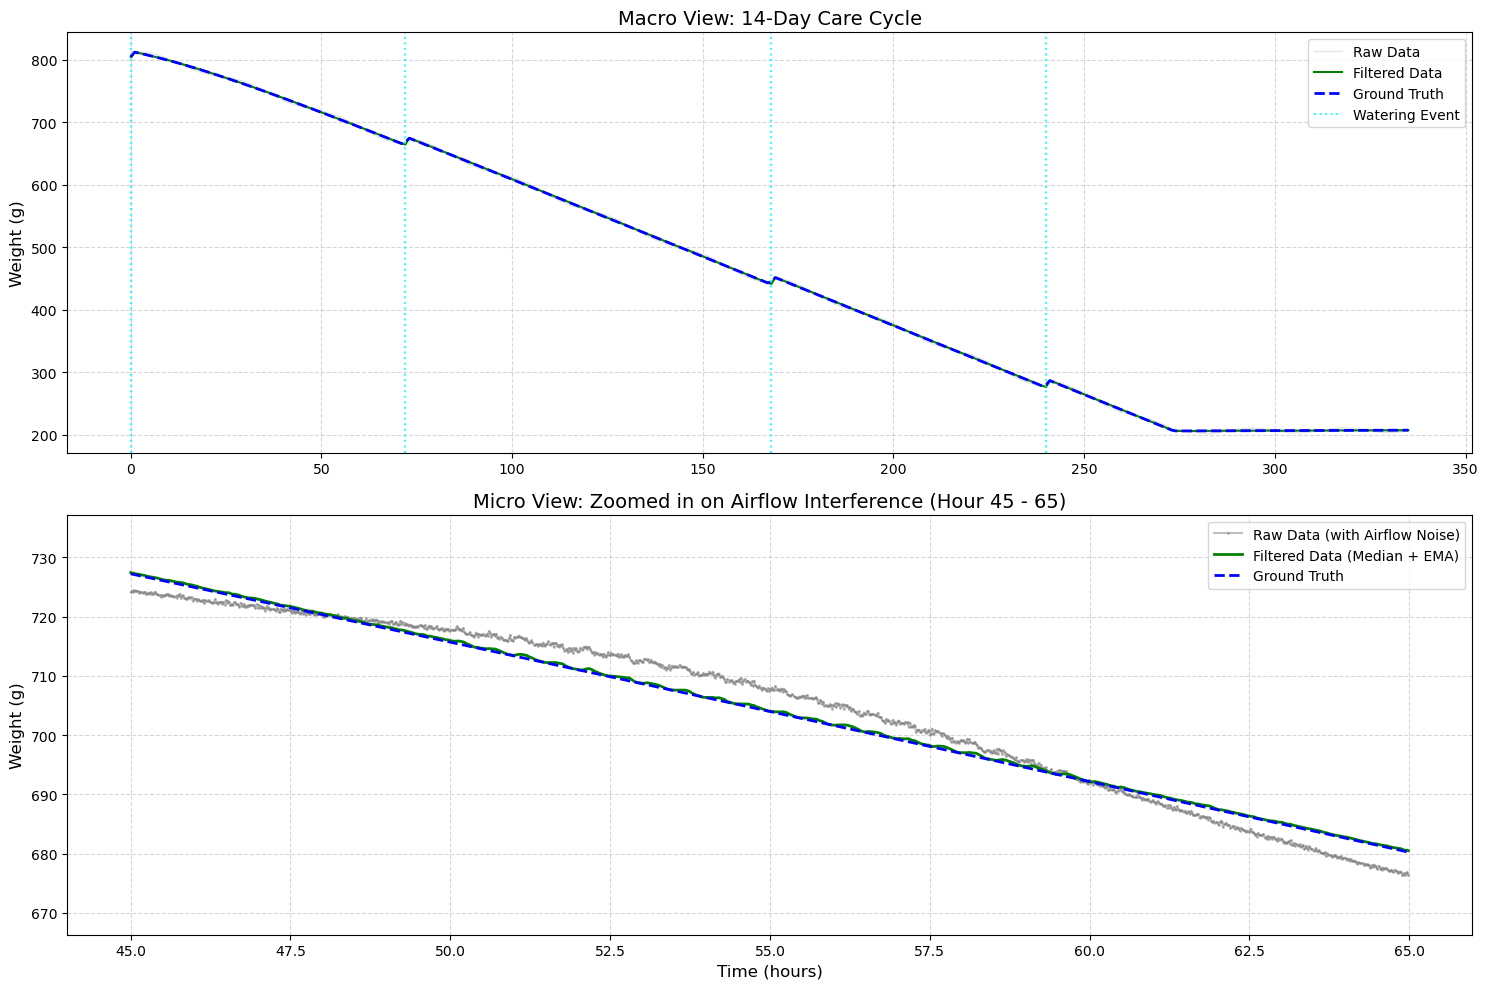

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import medfilt

# ==================== 1. Simulation Parameters ====================
# Removed np.random.seed() for stochastic robustness testing.
sampling_interval_hours = 1 / 60  # 1-minute sampling interval
total_hours = 24 * 14             # 14 days
n_samples = int(total_hours / sampling_interval_hours)
dt = sampling_interval_hours

noise_rms = 0.2                  # HX711 baseline noise ~0.2g RMS [citation:6]
alpha = 0.15                     # EMA smoothing factor
growth_rate_g_per_hour = 15.0 / (30 * 24)  # Plant growth baseline drift
watering_events_hours = [0, 72, 168, 240]  # Simulated watering events

# ==================== 2. Generate Ground Truth Weight ====================
t_hours = np.linspace(0, total_hours, n_samples)
true_weight = np.zeros(n_samples)
current_weight = 800.0
last_water_time = 0

for i, t in enumerate(t_hours):
    growth_offset = growth_rate_g_per_hour * t
    
    for w_time in watering_events_hours:
        if w_time <= t < w_time + 0.05:  # 3-minute soaking process
            current_weight += (800.0 / (0.05 * 60)) * dt
        elif t == w_time:
            last_water_time = t
    
    if t > last_water_time and not any(w <= t < w + 0.05 for w in watering_events_hours):
        time_since_water = t - last_water_time
        evaporation_rate = 2.5 * (1 - 0.5 * np.exp(-time_since_water / 24))
        current_weight -= evaporation_rate * dt
        current_weight = max(current_weight, 200.0)
        
    true_weight[i] = current_weight + growth_offset

# ==================== 3. Generate Noisy Observations ====================
# 3.1 Baseline Gaussian noise (HX711)
raw_noise = np.random.normal(0, noise_rms, n_samples)

# 3.2 Airflow interference (sinusoidal + random spikes)
airflow_noise = np.zeros(n_samples)
airflow_episodes = [(50, 60), (150, 165), (300, 315)]
for start, end in airflow_episodes:
    mask = (t_hours >= start) & (t_hours <= end)
    t_in_wind = t_hours[mask] - start
    airflow_noise[mask] = 0.3 * np.sin(2 * np.pi * t_in_wind * 2) + np.random.normal(0, 0.15, np.sum(mask))

# 3.3 Thermal drift (daily temperature cycle, simulated as sine wave)
thermal_drift = 4.0 * np.sin(2 * np.pi * t_hours / 24)

raw_weight = true_weight + raw_noise + airflow_noise + thermal_drift

# ==================== 4. Edge Computing Pipeline ====================
# Step 1: Thermal compensation (using DHT11 temperature data)
estimated_drift = thermal_drift * 0.99  # Assuming 99% compensation accuracy
compensated_weight = raw_weight - estimated_drift

# Step 2: Median filter for spike removal (kernel = 3 minutes)
filtered_median = medfilt(compensated_weight, kernel_size=3)

# Step 3: Exponential Moving Average (EMA) for baseline smoothing
ema_weight = np.zeros(n_samples)
ema_weight[0] = filtered_median[0]
for i in range(1, n_samples):
    ema_weight[i] = alpha * filtered_median[i] + (1 - alpha) * ema_weight[i - 1]

# ==================== 5. Performance Metrics ====================
rmse_raw = np.sqrt(np.mean((raw_weight - true_weight) ** 2))
rmse_ema = np.sqrt(np.mean((ema_weight - true_weight) ** 2))
noise_reduction_percent = (1 - rmse_ema / rmse_raw) * 100

print("=== Real-World Condition + Thermal Compensation Validation ===")
print(f"Raw Data RMSE: {rmse_raw:.4f} g")
print(f"Optimized Filtered RMSE: {rmse_ema:.4f} g")
print(f"Noise Reduction: {noise_reduction_percent:.2f}%")

# ==================== 6. Visualization ====================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10))
plot_step = 60

# --- Macro View ---
ax1.plot(t_hours[::plot_step], raw_weight[::plot_step], label='Raw Data', alpha=0.2, color='gray', linewidth=1)
ax1.plot(t_hours[::plot_step], ema_weight[::plot_step], label='Filtered Data', color='green', linewidth=1.5)
ax1.plot(t_hours[::plot_step], true_weight[::plot_step], label='Ground Truth', linestyle='--', color='blue', linewidth=2, zorder=5)

for w in watering_events_hours:
    ax1.axvline(x=w, color='cyan', linestyle=':', alpha=0.8, label='Watering Event' if w == 0 else "")

ax1.set_title('Macro View: 14-Day Care Cycle', fontsize=14)
ax1.set_ylabel('Weight (g)', fontsize=12)
ax1.legend(loc='upper right')
ax1.grid(True, linestyle='--', alpha=0.5)

# --- Micro View (Zoomed-in) ---
zoom_start, zoom_end = 45, 65
mask_zoom = (t_hours >= zoom_start) & (t_hours <= zoom_end)
t_zoom = t_hours[mask_zoom]
raw_zoom = raw_weight[mask_zoom]
ema_zoom = ema_weight[mask_zoom]
true_zoom = true_weight[mask_zoom]

ax2.plot(t_zoom, raw_zoom, label='Raw Data (with Airflow Noise)', alpha=0.5, color='gray', marker='.', markersize=2)
ax2.plot(t_zoom, ema_zoom, label='Filtered Data (Median + EMA)', color='green', linewidth=2)
ax2.plot(t_zoom, true_zoom, label='Ground Truth', linestyle='--', color='blue', linewidth=2, zorder=5)

y_min = min(true_zoom.min(), raw_zoom.min()) - 10
y_max = max(true_zoom.max(), raw_zoom.max()) + 10
ax2.set_ylim(y_min, y_max)

ax2.set_title(f'Micro View: Zoomed in on Airflow Interference (Hour {zoom_start} - {zoom_end})', fontsize=14)
ax2.set_xlabel('Time (hours)', fontsize=12)
ax2.set_ylabel('Weight (g)', fontsize=12)
ax2.legend(loc='upper right')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()